# Mouse stromal: cell-type annotation (stage 04c)

Every cluster of the re-integrated stromal lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_mouse_stromal.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/mouse_stromal.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "mouse", "stromal", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_mouse_stromal.h5ad"
TABLE = REPO / "resources/annotations/mouse_stromal.csv"
PANEL = ['Pdgfra', 'Col1a1', 'Col3a1', 'Dcn', 'Lum', 'Prl8a2', 'Ptgs2', 'Bmp2', 'Wnt4', 'Hand2', 'Mki67', 'Top2a', 'Cdh1', 'Pax8', 'Pecam1', 'Ptprc', 'Myh11', 'Sox6', 'Cdkn1a']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,efib_proliferative,780,leiden_scVI_3.0,"Pdgfra 0.74; Col1a1 0.61; Mki67 0.61; Top2a 0.79 | top vs lineage: Diaph3 0.85, Kif15 0.68, Knl1 0.65"
1,efib_subluminal,1610,leiden_scVI_3.0,"Pdgfra 0.68; Col1a1 0.52; Dcn 0.34; Prl8a2 0.01 | top vs lineage: Tmem132c 0.90, Galntl6 0.85, Tmem132cos 0.82 | position-named subtype: confirm on spatial map"
2,efib_subluminal,1296,leiden_scVI_3.0,"Pdgfra 0.58; Col1a1 0.42; Dcn 0.26; Prl8a2 0.00 | top vs lineage: Lsamp 0.92, Gria4 0.90, Rxfp1 0.90 | position-named subtype: confirm on spatial map"
3,efib_middle,927,leiden_scVI_3.0,"Pdgfra 0.68; Col1a1 0.45; Dcn 0.44; Prl8a2 0.00 | top vs lineage: Kcnd2 0.91, Ptch1 0.84, Mir99ahg 0.91 | position-named subtype: confirm on spatial map"
4,efib_middle,2068,leiden_scVI_3.0,"Pdgfra 0.68; Col1a1 0.44; Dcn 0.57; Prl8a2 0.01 | top vs lineage: Ebf1 0.95, Kcnd2 0.94, Nlgn1 0.88 | position-named subtype: confirm on spatial map"
5,efib_middle,1769,leiden_scVI_3.0,"Pdgfra 0.64; Col1a1 0.35; Dcn 0.33; Prl8a2 0.01 | top vs lineage: Kcnd2 0.94, Nlgn1 0.89, Mir99ahg 0.94 | position-named subtype: confirm on spatial map"
6,efib_subluminal,516,leiden_scVI_3.0,"Pdgfra 0.65; Col1a1 0.12; Dcn 0.17; Prl8a2 0.00 | top vs lineage: Rxfp1 0.94, Cdh11 0.96, Col6a4 0.88 | position-named subtype: confirm on spatial map"
7,efib_outer,1679,leiden_scVI_3.0,"Pdgfra 0.60; Col1a1 0.72; Dcn 0.51; Prl8a2 0.03 | top vs lineage: Col3a1 0.91, Celf2 0.90, Col1a2 0.84 | position-named subtype: confirm on spatial map"
8,efib_middle_induced,541,leiden_scVI_3.0,"Pdgfra 0.63; Col1a1 0.44; Prl8a2 0.00; Ptgs2 0.02 | top vs lineage: Palld 0.94, Pde7b 0.82, Camk1d 0.75 | position-named subtype: confirm on spatial map"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

43197 nuclei; 35 clusters
{'decidual_proliferative': 14434, 'efib_middle_induced': 8775, 'efib_middle': 4764, 'efib_subluminal': 3886, 'decidual_mature': 3856, 'decidual_boundary': 3722, 'efib_outer': 2073, 'decidual_apoptotic': 907, 'efib_proliferative': 780}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

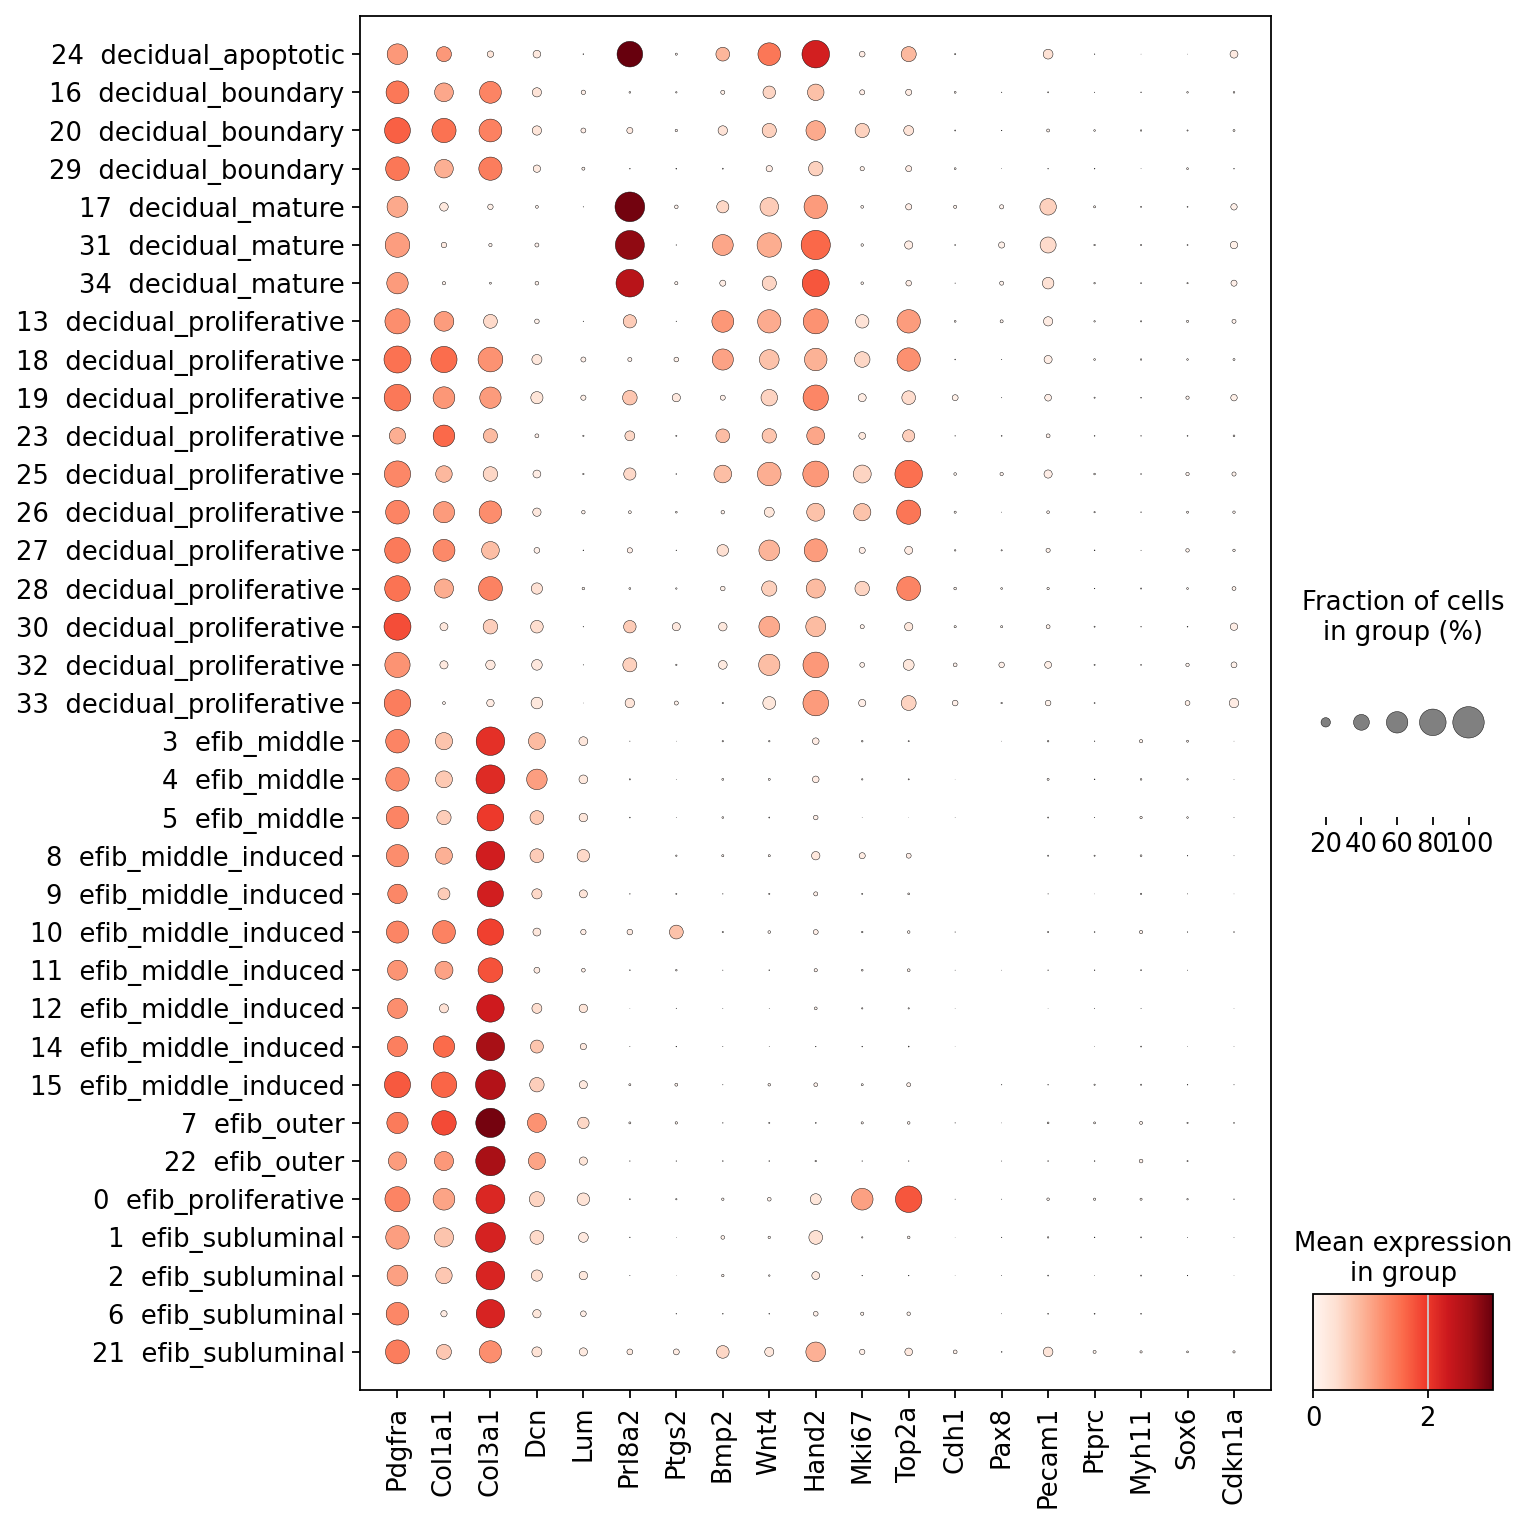

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference. A high doublet score together with markers of another lineage
(section 6) is what an EXCLUDE call rests on; a moderate score alone is not
(cycling clusters score around 1 throughout this dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
24,907,decidual_apoptotic,0.00,1279.0,2127.0
16,1153,decidual_boundary,0.00,1505.0,2261.0
20,552,decidual_boundary,0.41,1990.5,3195.5
29,2017,decidual_boundary,0.03,1660.0,2745.0
17,1747,decidual_mature,2.10,2417.0,6769.0
31,1832,decidual_mature,1.73,3094.5,8177.0
34,277,decidual_mature,0.00,1517.0,2797.0
13,1434,decidual_proliferative,1.78,2909.5,5892.0
18,1793,decidual_proliferative,1.94,2927.0,5965.0


## 5. UMAP by cluster and by label

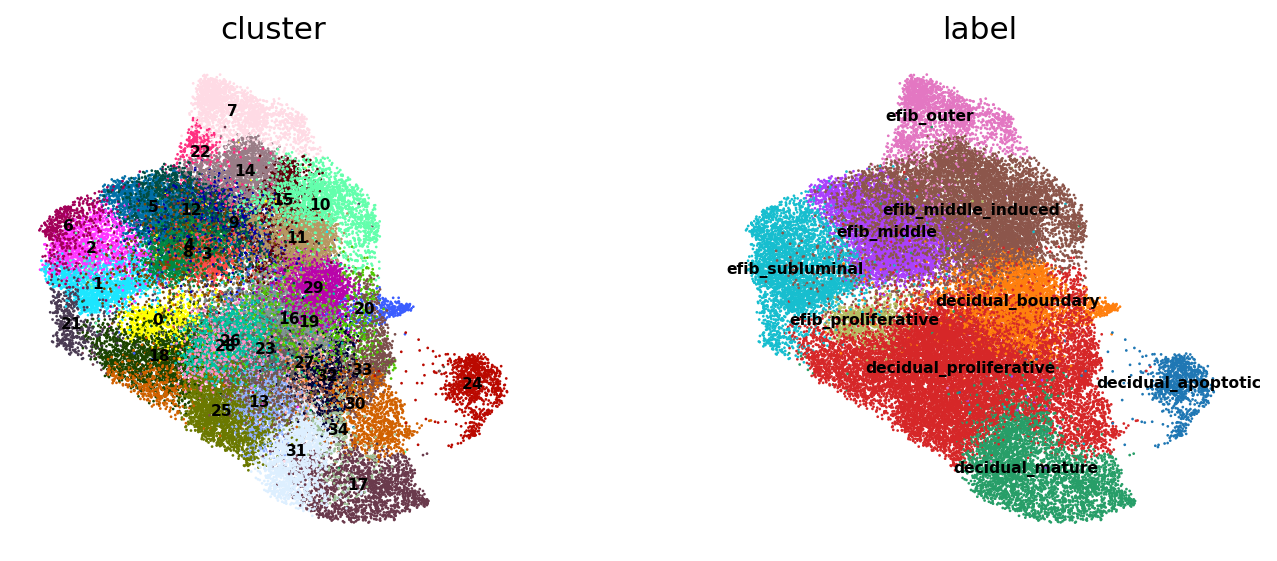

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

no EXCLUDE clusters in this table
